# 04 — Native range: is the Australian niche the same as the South American one?

Notebook 03 had a known weakness: **non-equilibrium**. The toad is still spreading in Australia, so a model trained only on Australian records may label places as "unsuitable" just because toads have not reached them yet. The native range gives an independent view of the species' climatic requirements.

Questions:
1. **Does the toad occupy the same climates in Australia as in its native range?** (niche comparison)
2. **What does a model trained in South America predict for Australia?** In particular, is the Pilbara suitable?
3. **Which suitability should feed the colonisation model (notebook 05)?**

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from download import GBIF_CITATION, download_australia_outline, download_countries
from environment import BIOCLIM_VARIABLES, environmental_grid
from front import AUSTRALIAN_ALBERS, records_to_cells
from native import (
    NATIVE_BBOX, SOUTH_AMERICA_ALBERS, andean_crest, load_native_records, native_grid, niche_density, schoener_d,
)

FIGURES = PROJECT_ROOT / "figures"
CELL_SIZE_M = 25_000
CLIMATE = list(BIOCLIM_VARIABLES.values())
print(GBIF_CITATION.read_text())

GBIF.org (2026-10-12) GBIF Occurrence Download https://doi.org/10.15468/dl.zh2ft4



## 1. Which toads count as "native"?

The name *Rhinella marina* used to cover populations from Texas to the Amazon. Acevedo et al. (2016) showed these are **two species**: *R. marina* sensu stricto east of the Andes, and *R. horribilis* west of the Andes, from Mexico and Central America to the west slope of the Venezuelan Andes and western and northern Colombia (Amphibian Species of the World). In 2024, the western Ecuador populations were described as a third species, *R. bella*.

**Australian toads descend from *R. marina* sensu stricto** (they came via Hawaii and Puerto Rico from the Guianas region), so that is the native niche we need. Many GBIF records still use the old name for western toads, so we filter by geography:

| Filter | Rule | Why |
|---|---|---|
| East of the Andes | Longitude east of the Andean crest, defined as the easternmost point above 2,000 m in each 0.5° latitude band; north of 10°N, east of 71.5°W (excludes northern Colombia and the Maracaibo basin) | Removes *R. horribilis* and *R. bella* |
| Latitude ≥ 20°S | | Records further south (southern Brazil, Paraguay, Argentina) are most likely other *Rhinella* species misidentified |
| Country | Excludes Argentina, Uruguay, Paraguay, Chile and Caribbean islands where the toad was introduced (Aruba, Martinique, Curaçao, Bonaire) | Outside the native range |
| Year ≥ 1970 | | Matches the WorldClim climate period and avoids old, imprecise georeferencing |
| Coordinate uncertainty ≤ 10 km (or unknown) | | Same criterion as notebook 01 |

This is a **conservative approximation**: it drops some genuine records to avoid mixing in other species.

In [2]:
records = load_native_records()
steps = ["east_of_andes", "in_latitude_range", "country_ok", "recent", "precise"]
keep = np.ones(len(records), dtype=bool)
funnel = {"GBIF records (South America)": len(records)}
for step in steps:
    keep &= records[step].to_numpy()
    funnel[step] = keep.sum()
records["native"] = keep
pd.Series(funnel, name="records").to_frame()

,records
GBIF records (South America),13251
east_of_andes,10624
in_latitude_range,10552
country_ok,10508
recent,9499
precise,9195


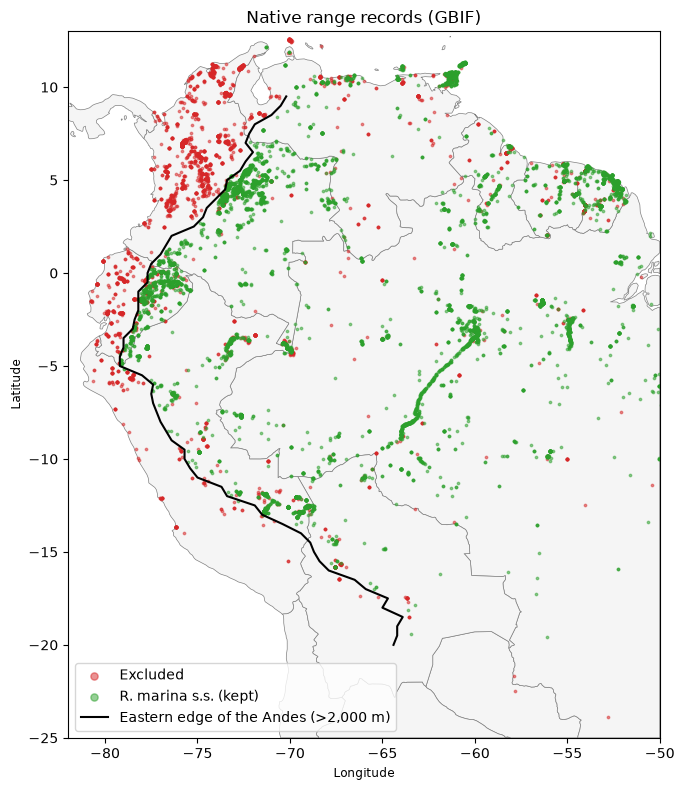

In [3]:
crest = andean_crest()
countries = download_countries().clip(NATIVE_BBOX)

fig, ax = plt.subplots(figsize=(8, 8))
countries.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
excluded = records.loc[~records["native"]]
kept = records.loc[records["native"]]
ax.scatter(excluded["decimalLongitude"], excluded["decimalLatitude"], s=3, c="tab:red", alpha=0.5, label="Excluded")
ax.scatter(kept["decimalLongitude"], kept["decimalLatitude"], s=3, c="tab:green", alpha=0.5, label="R. marina s.s. (kept)")
ax.plot(crest.to_numpy(), crest.index, color="black", linewidth=1.5, label="Eastern edge of the Andes (>2,000 m)")
ax.set(xlim=NATIVE_BBOX[0::2], ylim=NATIVE_BBOX[1::2], xlabel="Longitude", ylabel="Latitude",
       title="Native range records (GBIF)")
ax.legend(loc="lower left", markerscale=3)
plt.tight_layout()
plt.savefig(FIGURES / "04_native_records.png", dpi=150)

## 2. Native grid and accessible area

Same 25 km grid and WorldClim variables as in Australia, in a South American equal-area projection. The **background** is limited to the **accessible area** (cells within 500 km of a native record): places the toad could plausibly have reached. Including the whole continent would make the model learn "where toads could never disperse to" instead of "which climates they avoid" (Barve et al. 2011).

In [4]:
ACCESSIBLE_KM = 500

native = native_grid(CELL_SIZE_M)
points = gpd.GeoDataFrame(
    kept, geometry=gpd.points_from_xy(kept["decimalLongitude"], kept["decimalLatitude"]), crs=4326
).to_crs(SOUTH_AMERICA_ALBERS)
native_cells = pd.DataFrame({
    "cx": (points.geometry.x // CELL_SIZE_M).astype(int),
    "cy": (points.geometry.y // CELL_SIZE_M).astype(int),
}).drop_duplicates().assign(toad=1)
native = native.merge(native_cells, how="left", on=["cx", "cy"]).fillna({"toad": 0})

distance_cells, _ = cKDTree(native.loc[native["toad"] == 1, ["cx", "cy"]]).query(native[["cx", "cy"]])
native = native.loc[distance_cells * CELL_SIZE_M / 1000 <= ACCESSIBLE_KM].reset_index(drop=True)

australia = environmental_grid(CELL_SIZE_M)
toad_cells = records_to_cells(
    pd.read_csv(PROJECT_ROOT / "data" / "processed" / "rhinella_marina_clean.csv"), CELL_SIZE_M
)[["cx", "cy"]].assign(toad=1)
australia = australia.merge(toad_cells, how="left", on=["cx", "cy"]).fillna({"toad": 0})

print(f"Native: {len(native):,} accessible cells, {int(native['toad'].sum()):,} with toads")
print(f"Australia: {len(australia):,} cells, {int(australia['toad'].sum()):,} with toads")

Native: 16,296 accessible cells, 1,046 with toads
Australia: 12,312 cells, 1,310 with toads


## 3. A first look: where does the toad live in each continent?

In [5]:
pilbara = australia["lon"].between(116, 121) & australia["lat"].between(-23, -19)
pd.DataFrame({
    "native range (toad cells)": native.loc[native["toad"] == 1, CLIMATE].median(),
    "Australia (toad cells)": australia.loc[australia["toad"] == 1, CLIMATE].median(),
    "Pilbara (no toads yet)": australia.loc[pilbara, CLIMATE].median(),
}).round(0)

,native range (toad cells),Australia (toad cells),Pilbara (no toads yet)
annual_mean_temp,26.0,24.0,26.0
max_temp_warmest_month,32.0,34.0,40.0
min_temp_coldest_month,20.0,11.0,11.0
annual_precip,2303.0,836.0,341.0
precip_seasonality,50.0,101.0,93.0
precip_driest_quarter,223.0,25.0,10.0


Medians of each climate variable. **In Australia the toad lives in climates that are much drier and more seasonal than in its native range**: about a third of the annual rainfall, a dry season roughly ten times drier, and winters 9 °C colder. The Pilbara is drier still.

## 4. Niche comparison in environmental space (PCA-env)

Following Broennimann et al. (2012):

1. A **PCA** of the 6 climate variables, calibrated on the backgrounds of both continents. This gives a shared "climate space" with two axes.
2. In that space, a kernel density of the **occupied** cells, divided by the density of the **available** climates. This corrects for the fact that some climates are simply more common in one continent.
3. **Schoener's D** measures overlap between the two niches: 0 = no overlap, 1 = identical.

We also report the **unfilling / stability / expansion** decomposition (Guisan et al. 2014), restricted to climates available in both continents:
- **Expansion:** share of the Australian niche in climates the toad does not occupy in its native range.
- **Unfilling:** share of the native niche not (yet) occupied in Australia.

⚠️ This is a simplified Python implementation of the method (the reference implementation is the R package `ecospat`). Thresholds for "occupied" and "available" (5% and 0.1% of the maximum density) are our choice.

In [6]:
background = pd.concat([native[CLIMATE], australia[CLIMATE]])
scaler = StandardScaler().fit(background)
pca = PCA(n_components=2).fit(scaler.transform(background))
to_pcs = lambda df: pca.transform(scaler.transform(df[CLIMATE]))
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(2))
pd.DataFrame(pca.components_.T, index=CLIMATE, columns=["PC1", "PC2"]).round(2)

Variance explained by PC1, PC2: [0.48 0.32]


,PC1,PC2
annual_mean_temp,0.41,0.51
max_temp_warmest_month,0.05,0.61
min_temp_coldest_month,0.54,0.18
annual_precip,0.53,-0.18
precip_seasonality,-0.19,0.42
precip_driest_quarter,0.47,-0.35


In [7]:
all_scores = np.vstack([to_pcs(native), to_pcs(australia)])
axes_grid = [np.linspace(all_scores[:, i].min(), all_scores[:, i].max(), 100) for i in range(2)]

z_native, available_native = niche_density(to_pcs(native.loc[native["toad"] == 1]), to_pcs(native), axes_grid)
z_australia, available_australia = niche_density(
    to_pcs(australia.loc[australia["toad"] == 1]), to_pcs(australia), axes_grid
)

OCCUPIED, AVAILABLE = 0.05, 0.001
analog = (available_native > AVAILABLE) & (available_australia > AVAILABLE)
invaded_analog = z_australia * analog
native_analog = z_native * analog
niche_metrics = {
    "Schoener's D": schoener_d(z_native, z_australia),
    "expansion": (invaded_analog * (z_native <= OCCUPIED)).sum() / invaded_analog.sum(),
    "unfilling": (native_analog * (z_australia <= OCCUPIED)).sum() / native_analog.sum(),
    "Australian niche in non-analog climates": (z_australia * ~analog).sum() / z_australia.sum(),
}
niche_metrics["stability"] = 1 - niche_metrics["expansion"]
pd.Series(niche_metrics).round(2)

Schoener's D                               0.09
expansion                                  0.77
unfilling                                  0.30
Australian niche in non-analog climates    0.07
stability                                  0.23
dtype: float64

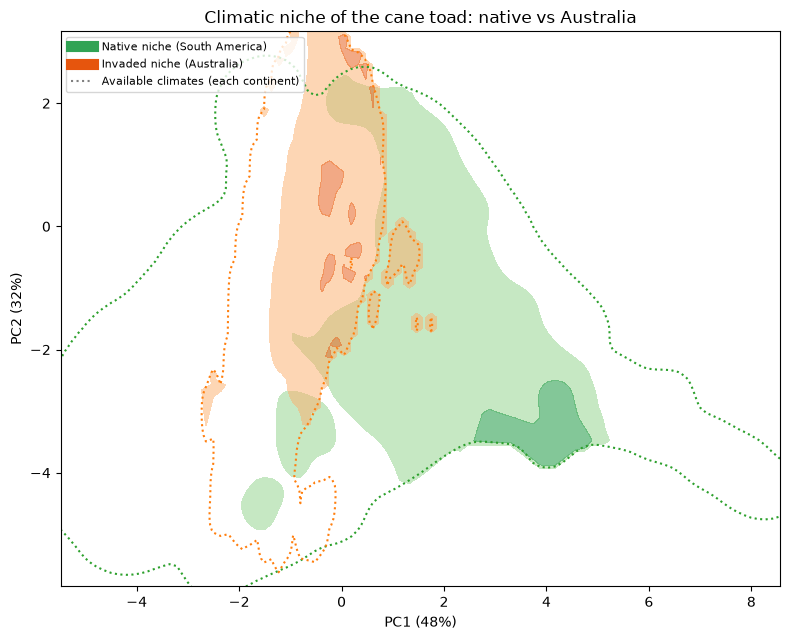

In [8]:
fig, ax = plt.subplots(figsize=(8, 6.5))
extent = [axes_grid[0][0], axes_grid[0][-1], axes_grid[1][0], axes_grid[1][-1]]
ax.contour(axes_grid[0], axes_grid[1], available_native.T, levels=[AVAILABLE], colors="tab:green", linestyles="dotted")
ax.contour(axes_grid[0], axes_grid[1], available_australia.T, levels=[AVAILABLE], colors="tab:orange", linestyles="dotted")
ax.contourf(axes_grid[0], axes_grid[1], z_native.T, levels=[OCCUPIED, 0.5, 1], colors=["#a1d99b", "#31a354"], alpha=0.6)
ax.contourf(axes_grid[0], axes_grid[1], z_australia.T, levels=[OCCUPIED, 0.5, 1], colors=["#fdae6b", "#e6550d"], alpha=0.5)
ax.plot([], [], color="#31a354", linewidth=8, label="Native niche (South America)")
ax.plot([], [], color="#e6550d", linewidth=8, label="Invaded niche (Australia)")
ax.plot([], [], color="grey", linestyle="dotted", label="Available climates (each continent)")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
       title="Climatic niche of the cane toad: native vs Australia")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "04_niche_comparison.png", dpi=150)

**The two niches barely overlap** (D ≈ 0.1), and most of the Australian niche lies in climates that are available in South America but that the toad does not occupy there (**expansion**). In Australia the toad lives in drier, more seasonal climates than anywhere in its native range.

This agrees with Tingley et al. (2014), who concluded that in its native range the toad is limited by **biotic interactions** (competitors, predators, parasites), while in Australia, free of them, it fills a much larger part of its physiological potential.

## 5. Projecting the native model onto Australia

The same logistic regression as in notebook 03 (6 climate variables with quadratic terms), trained on native presences vs the accessible background, with spatial block CV, then projected onto Australia.

In [9]:
def logistic():
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000))


native["block"] = (native["cx"] // 20).astype(str) + "_" + (native["cy"] // 20).astype(str)
cv_auc = [
    roc_auc_score(
        native.loc[test, "toad"],
        logistic().fit(native.loc[train, CLIMATE], native.loc[train, "toad"]).predict_proba(native.loc[test, CLIMATE])[:, 1],
    )
    for train, test in GroupKFold(5).split(native, native["toad"], native["block"])
]
print(f"Native model, spatial CV AUC in South America: {np.mean(cv_auc):.3f} ± {np.std(cv_auc):.3f}")

models = {
    "Australia only": (australia, logistic().fit(australia[CLIMATE], australia["toad"])),
    "Native only": (native, logistic().fit(native[CLIMATE], native["toad"])),
}
pooled = pd.concat([native[CLIMATE + ["toad"]], australia[CLIMATE + ["toad"]]])
models["Pooled (native + Australia)"] = (pooled, logistic().fit(pooled[CLIMATE], pooled["toad"]))

for name, (training, model) in models.items():
    threshold = np.quantile(model.predict_proba(training.loc[training["toad"] == 1, CLIMATE])[:, 1], 0.10)
    australia[f"score ({name})"] = model.predict_proba(australia[CLIMATE])[:, 1]
    australia[f"suitable ({name})"] = australia[f"score ({name})"] >= threshold

Native model, spatial CV AUC in South America: 0.702 ± 0.090


The native model is weaker in its own range (AUC ≈ 0.70 vs ≈ 0.93 in Australia): native records are sparse and the toad occupies most of the humid lowlands, so presences and background look alike.

Three suitability models for Australia (all climate-only, so they are comparable across continents):
- **Australia only:** learns the niche observed in Australia (notebook 03 without elevation and rivers).
- **Native only:** learns the niche observed in South America.
- **Pooled:** both ranges together, as recommended by Broennimann & Guisan (2008) to capture the most complete picture of the niche.

In [10]:
regions = {
    "Current toad cells": australia["toad"] == 1,
    "Kimberley (behind the western front)": australia["lon"].between(124, 128) & australia["lat"].between(-18, -15),
    "Pilbara (ahead of the western front)": pilbara,
    "South-west WA (Perth)": (australia["lon"] < 118) & (australia["lat"] < -30),
}
summary = pd.DataFrame({
    name: {"% of Australia suitable": 100 * australia[f"suitable ({name})"].mean()}
    | {f"% suitable: {region}": 100 * australia.loc[mask, f"suitable ({name})"].mean() for region, mask in regions.items()}
    | {"AUC on Australian toad cells": roc_auc_score(australia["toad"], australia[f"score ({name})"])}
    for name in models
}).round(2)
summary

,Australia only,Native only,Pooled (native + Australia)
% of Australia suitable,22.12,0.85,36.70
% suitable: Current toad cells,90.00,2.21,97.02
% suitable: Kimberley (behind the western front),85.85,0.00,100.00
% suitable: Pilbara (ahead of the western front),0.00,0.00,4.80
% suitable: South-west WA (Perth),0.00,0.00,0.00
AUC on Australian toad cells,0.94,0.81,0.92


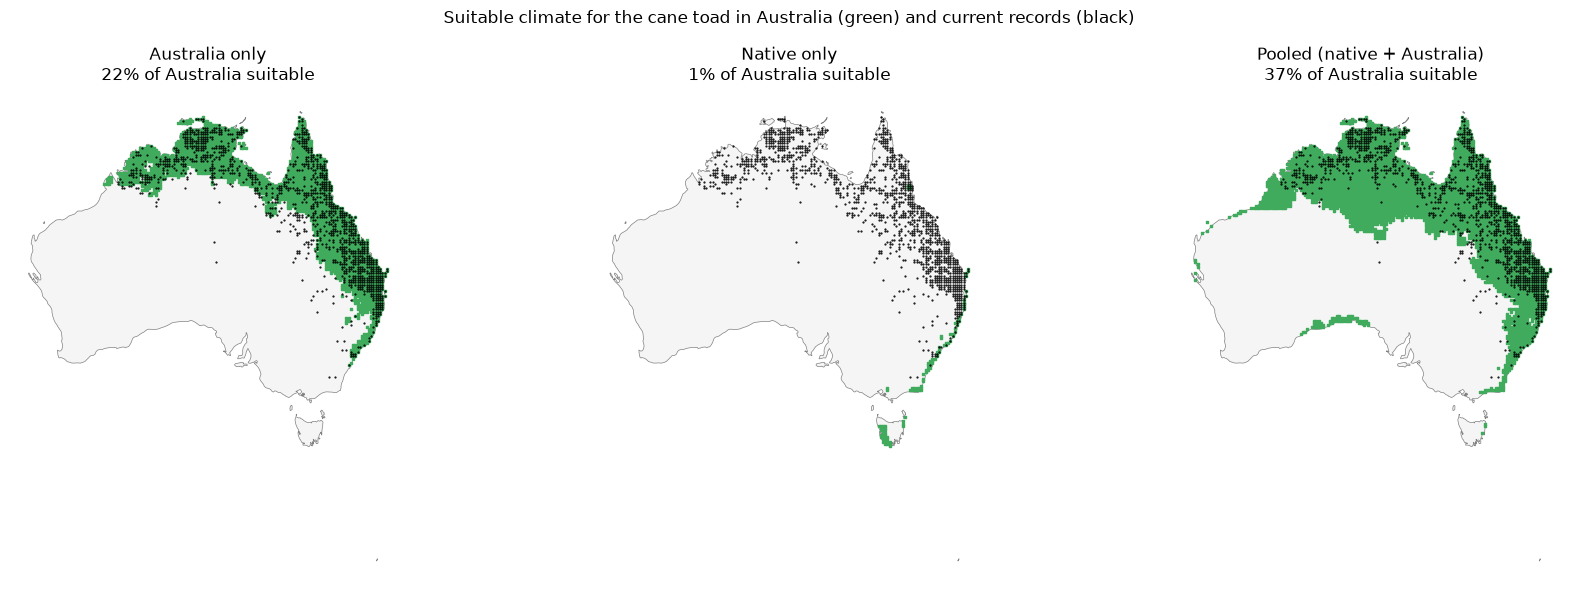

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
outline = download_australia_outline().to_crs(AUSTRALIAN_ALBERS)
x = (australia["cx"] + 0.5) * CELL_SIZE_M
y = (australia["cy"] + 0.5) * CELL_SIZE_M
toads = australia["toad"] == 1
for ax, name in zip(axes, models):
    outline.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
    suitable = australia[f"suitable ({name})"]
    ax.scatter(x[suitable], y[suitable], s=1.6, marker="s", c="#41ab5d")
    ax.scatter(x[toads], y[toads], s=0.3, c="black")
    ax.set_axis_off()
    ax.set_title(f"{name}\n{100 * suitable.mean():.0f}% of Australia suitable")
fig.suptitle("Suitable climate for the cane toad in Australia (green) and current records (black)")
plt.tight_layout()
plt.savefig(FIGURES / "04_suitability_three_models.png", dpi=150)

## Conclusions

1. **The native niche cannot tell us where the toad can live in Australia.** A model trained in South America rates only a tiny fraction of the cells the toad *already occupies* in Australia as suitable. The toad has **expanded its realised niche** into drier, more seasonal climates (Tingley et al. 2014). Interestingly, the native model still *ranks* Australian cells reasonably well (AUC ≈ 0.8): it gets the direction right (warmer and wetter is better) but not the limits.
2. **The Australian model is therefore the better guide, but it is a lower bound.** If the niche expanded once, it can keep expanding. The pooled model, which learns from both ranges, rates **37%** of Australia as suitable (vs 22% for the Australian-only model) and a small part of the **Pilbara (≈5%)**.
3. **The Pilbara is a strong but not absolute barrier.** None of the models rate it as broadly suitable; the pooled one opens a few pockets. That matches Tingley et al. (2013): crossing the Pilbara would depend on artificial water.

**Decision for notebook 05:** run the colonisation model under **two suitability scenarios**:
- **"Observed niche":** Australian-only model (conservative).
- **"Expanded niche":** pooled model (permissive).

The difference between them is a key part of the forecast uncertainty.

**Limitations:** the native filter is a geographic approximation of a taxonomic boundary; native records are sparse and biased towards accessible areas; climate-only models (no water, no land cover); a 25 km grid; climate normals for 1970–2000.